![Banner](../images/09_02_banner_rs_optical.png)


# Preprocessing of Optical Images

Analysis-ready data rarely arrive ready for *your* analysis.


## Overview

Haze, terrain shading, clouds, mismatched resolutions and small geometric offsets all bias results. This module works through the main corrections with real data and, wherever possible, **measures** how well each one works.


## Core concepts

### Learning objectives

1. Follow the radiometric chain DN → radiance → TOA → surface reflectance, and apply DOS1.
2. Estimate sun geometry from an image and correct terrain illumination (cosine, C, Minnaert, SCS+C).
3. Compare cloud-free compositing methods on a real Sentinel-2 series.
4. Pan-sharpen and evaluate the result with Wald's protocol and ERGAS.
5. Detect and correct sub-pixel misregistration.
6. Estimate sub-pixel land-cover fractions with linear spectral unmixing, and validate them.

### Data

| Data | Use |
|---|---|
| Sentinel-2 L1C time series, Slovenia (eo-learn, 68 dates) | DOS1, compositing, co-registration |
| Landsat 7 5-year composite + 90 m DEM, central Sierra Nevada | Topographic correction |
| Landsat 9 L2 surface reflectance, Las Vegas, 8 Jul 2024 + NLCD 2021 | Pan-sharpening, unmixing |

### Contents

1. Data
2. Setup
3. Radiometric correction and DOS1
4. Topographic correction
5. Cloud-free compositing
6. Pan-sharpening and Wald's protocol
7. Co-registration
8. Linear spectral unmixing
9. Summary, exercises and references


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore", category=UserWarning)  # hide routine library warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)  # e.g. "mean of empty slice" in all-NaN areas

import json  # read JSON metadata
import numpy as np  # arrays
import pandas as pd  # tables
import xarray as xr  # labelled rasters
import geopandas as gpd  # vector data
import rasterio  # raster reading
import matplotlib.pyplot as plt  # figures
from rasterio.enums import Resampling  # resampling methods

import geolattice.rsense as rs  # GeoLattice remote sensing tools

rasterio.Env(CPL_LOG="/dev/null").__enter__()  # silence GDAL log messages for the whole session
plt.rcParams.update({"figure.dpi": 110})  # figure resolution

In [2]:
from pathlib import Path  # file paths
import urllib.request  # download files over HTTP

# The notebook's data folder: ../../../../Data/08_remote_sensing/08_02_optical/ next to this notebook, found from here or from the repository root.
DATA = next((p for p in (Path("Data/08_remote_sensing/08_02_optical"), Path("../../../../Data/08_remote_sensing/08_02_optical"))
             if p.is_dir()), Path("../../../../Data/08_remote_sensing/08_02_optical"))
DATA.mkdir(exist_ok=True)  # create it if needed
GH = "https://github.com/opengeos/datasets/releases/download"  # base URL of the opengeos datasets release
RAW = "https://raw.githubusercontent.com"  # base URL for raw GitHub files
# the eo-learn test patch (Sentinel-2 time series)
EOP = f"{RAW}/sentinel-hub/eo-learn/develop/example_data/TestEOPatch"
URLS = {  # file name -> download URL
    # Landsat 9 C2 L2 surface reflectance, 8 July 2024, Las Vegas (90 m, 7 bands)
    "landsat_las_vegas.tif": f"{GH}/raster/landsat_las_vegas.tif",
    # Landsat annual composites over Pucallpa, Peru (SWIR1, NIR, Red, Green; 8-bit)
    **{f"pucallpa_{y}.tif": f"{RAW}/opengeos/data/main/landsat/{y}.tif" for y in range(1985, 2021, 5)},
    # ECOSTRESS L2T land surface temperature (70 m), southern California, 1 April 2023
    "ecostress_lst.tif": f"{GH}/raster/ECOv002_L2T_LSTE_26860_001_10SGD_20230401T203733_0710_01_LST.tif",
    # Landsat 7 composite + 90 m DEM, central Sierra Nevada (same grid family as Part I)
    "landsat.tif": f"{GH}/raster/landsat.tif",
    "dem_90m.tif": f"{GH}/book/dem_90m.tif",
    "cog.tif": f"{GH}/raster/cog.tif",
    # Real Sentinel-2 L1C time series (eo-learn TestEOPatch, Slovenia, 68 dates, 13 bands)
    "s2_bands.npy": f"{EOP}/data/BANDS-S2-L1C.npy",
    "s2_clp.npy": f"{EOP}/data/CLP.npy",
    "s2_clm.npy": f"{EOP}/mask/CLM.npy",
    "s2_lulc.npy": f"{EOP}/mask_timeless/LULC.npy",
    "s2_dem.npy": f"{EOP}/data_timeless/DEM.npy",
    "s2_timestamps.json": f"{EOP}/timestamps.json",
    "s2_bbox.geojson": f"{EOP}/bbox.geojson",
}

def fetch(name):  # download helper
    """Download a tutorial dataset once and return its local path."""
    path = DATA / name  # local path
    if not path.exists():  # download only if missing
        print(f"Downloading {name} ...")  # progress message
        urllib.request.urlretrieve(URLS[name], path)  # copy the URL to the local path
    return path  # the local path

NLCD_URL = f"{GH}/raster/nlcd_2021_land_cover_90m.tif"  # NLCD 2021 land cover (90 m), read remotely
NLCD_CLASSES = {11: ("Open water", "#466b9f"), 21: ("Developed, open", "#dec5c5"),
                22: ("Developed, low", "#d99282"), 23: ("Developed, medium", "#eb0000"),
                24: ("Developed, high", "#ab0000"), 31: ("Barren", "#b3ac9f"),
                41: ("Deciduous forest", "#68ab5f"), 42: ("Evergreen forest", "#1c5f2c"),
                43: ("Mixed forest", "#b5c58f"), 52: ("Shrub/scrub", "#ccb879"),
                71: ("Grassland", "#dfdfc2"), 81: ("Pasture/hay", "#dcd939"),
                82: ("Cultivated crops", "#ab6c28"), 90: ("Woody wetlands", "#b8d9eb"),
                95: ("Herbaceous wetlands", "#6c9fb8")}

def nlcd_for(template, name="nlcd_window"):  # NLCD land cover on the grid of another raster
    """NLCD 2021 land cover on the grid of `template`.

    Reads only the needed window of the 200 MB CONUS COG over HTTP (cloud-native), then
    nearest-neighbour resamples it onto the template grid. Cached in ../../../../Data/08_remote_sensing/08_02_optical/.
    """
    from rasterio.enums import Resampling  # nearest-neighbour resampling for classes
    cache = DATA / f"{name}.tif"  # cached local window
    if not cache.exists():  # only read the remote file once
        import rasterio, rioxarray  # raster readers
        from rasterio.warp import transform_bounds  # reproject a bounding box
        with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"):  # do not list the remote folder (faster)
            src = rioxarray.open_rasterio("/vsicurl/" + NLCD_URL)  # open the remote GeoTIFF lazily
            # bounds of the template in the NLCD CRS
            b = transform_bounds(template.rio.crs, src.rio.crs, *template.rio.bounds())
            win = src.rio.clip_box(*b).squeeze("band", drop=True).load()  # read only that window
        rs.write(win, cache, cog=False)  # cache it
    # read the cached window; 0 = no data
    win = rs.read(cache, masked=False).squeeze("band", drop=True).rio.write_nodata(0)
    # resample onto the template grid (nearest)
    out = win.rio.reproject_match(template, resampling=Resampling.nearest, nodata=0)
    return out.astype("int16").rio.write_nodata(0)  # as 16-bit integers with 0 as no-data

In [3]:
# Real Sentinel-2 L1C cube (same construction as Module 7)
b = np.load(fetch("s2_bands.npy")); clp = np.load(fetch("s2_clp.npy"))[..., 0]
times = pd.to_datetime(json.load(open(fetch("s2_timestamps.json"))))  # acquisition dates of the time series
bb = json.load(open(fetch("s2_bbox.geojson")))["coordinates"][0]  # the patch's bounding polygon
# the 13 Sentinel-2 band names
names = ["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B09", "B10", "B11", "B12"]
x = min(p[0] for p in bb) + 10 * (np.arange(b.shape[2]) + 0.5)  # x coordinates of pixel centres (10 m pixels)
y = max(p[1] for p in bb) - 10 * (np.arange(b.shape[1]) + 0.5)  # y coordinates of pixel centres
# bands as variables of a Dataset (time, y, x)
s2 = xr.Dataset({n: (("time", "y", "x"), b[..., i]) for i, n in enumerate(names)},
                coords={"time": times, "y": y, "x": x}).rio.write_crs(32633)
s2.attrs["pyrsense:sensor"] = "sentinel2"  # record the sensor
from scipy.ndimage import binary_dilation  # grow masks by a few pixels
# clear = cloud probability below 0.4, cloud edges included
clear = xr.DataArray(~np.stack([binary_dilation(p > 0.4, iterations=2) for p in clp]),
                     dims=("time", "y", "x"), coords=s2[["B02"]].coords)
s2c = s2.where(clear)  # cloudy pixels -> NaN
print(s2.sizes)  # dimensions

Frozen({'time': 68, 'y': 101, 'x': 100})


## Radiometric correction and DOS1

The chain from raw counts to surface reflectance:

1. **DN → radiance**: `L = M·DN + A` (gain/offset from metadata): `rs.optical.radiance`
2. **Radiance → TOA reflectance**: divide by solar irradiance and sun angle: `rs.optical.toa_reflectance`
3. **TOA → surface reflectance**: remove atmospheric scattering and absorption with a radiative
   transfer model (6S, LaSRC for Landsat, Sen2Cor for Sentinel-2).

Agencies now distribute surface reflectance, so step 3 is usually done for you. When it isn't
(historical archives, commercial imagery), **Dark Object Subtraction (DOS1)** is a robust
first-order correction: the darkest pixels in each band should be nearly black, so any excess
brightness is atmospheric path radiance.


In [4]:
# the least cloudy July or August date
k = int(np.argmin(np.where(times.month.isin([7, 8]), clp.mean((1, 2)), 9)))
toa = s2.isel(time=k)[["B02", "B03", "B04", "B08"]]  # top-of-atmosphere blue, green, red and NIR of that date
dos = rs.optical.dos1(toa, percentile=0.5)  # dark-object subtraction (DOS1) using the 0.5th percentile
# darkest values before and after
tab = pd.DataFrame({"TOA dark (0.5th pct)": [float(np.nanpercentile(toa[v], 0.5)) for v in toa.data_vars],
                    "after DOS1": [float(np.nanpercentile(dos[v], 0.5)) for v in toa.data_vars]},
                   index=["blue", "green", "red", "NIR"]).round(4)
tab["path radiance removed"] = (tab.iloc[:, 0] - tab.iloc[:, 1]).round(4)  # the path radiance that was removed
tab  # show the table

,TOA dark (0.5th pct),after DOS1,path radiance removed
blue,0.0650,0.01,0.0550
green,0.0483,0.01,0.0383
red,0.0268,0.01,0.0168
NIR,0.1418,0.01,0.1318


Look at the NIR row: DOS1 removed 0.13 of "path radiance" from NIR, far more than from blue.
That is physically impossible (scattering falls with wavelength). The method assumes every band
contains a truly dark object; in this 1 km² of forest and meadow there is no water or deep
shadow, so the darkest NIR pixels are still vegetation. The fix is to apply DOS only to bands
where dark objects exist (here the visible bands) and leave NIR unchanged.


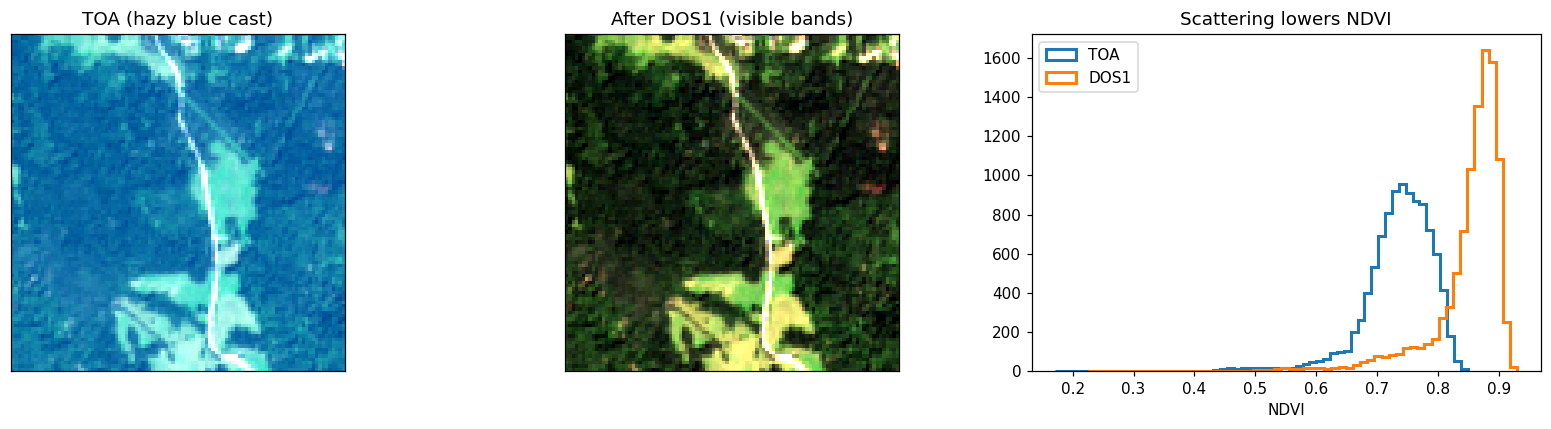

Mean NDVI: TOA 0.734 → DOS1 0.849


In [5]:
# DOS1 on the visible bands only, NIR unchanged
dos = rs.optical.dos1(toa[["B02", "B03", "B04"]], percentile=0.5).merge(toa[["B08"]])
ndvi_toa = rs.optical.index(toa, "NDVI")  # NDVI from TOA reflectance
ndvi_dos = rs.optical.index(dos, "NDVI")  # NDVI after DOS1
fig, axes = plt.subplots(1, 3, figsize=(15, 4))  # three panels
# TOA true colour
rs.viz.plot_rgb(toa, ["B04", "B03", "B02"], ax=axes[0], per_band=False, title="TOA (hazy blue cast)")
# after DOS1
rs.viz.plot_rgb(dos, ["B04", "B03", "B02"], ax=axes[1], per_band=False, title="After DOS1 (visible bands)")
axes[2].hist(ndvi_toa.values.ravel(), 60, histtype="step", label="TOA", lw=2)  # NDVI histogram, TOA
axes[2].hist(ndvi_dos.values.ravel(), 60, histtype="step", label="DOS1", lw=2)  # NDVI histogram, DOS1
axes[2].set(xlabel="NDVI", title="Scattering lowers NDVI"); axes[2].legend()  # labels, title and legend
for a in axes[:2]: a.set_xticks([]); a.set_yticks([])  # no ticks on the images
plt.tight_layout(); plt.show()  # arrange and draw
# mean NDVI before and after
print(f"Mean NDVI: TOA {float(ndvi_toa.mean()):.3f} → DOS1 {float(ndvi_dos.mean()):.3f}")

Scattering is strongest at short wavelengths (blue > green > red), so DOS1 removes most from
blue. Because path radiance inflates red while NIR is almost unaffected, TOA NDVI is biased low
and the correction raises it. Always compare indices across dates on surface reflectance, not
TOA, and sanity-check any image-based correction against physics.


## Topographic correction

On slopes facing the sun, pixels receive more light than on slopes facing away, so the *same*
forest looks brighter or darker depending on aspect. The local illumination is

$$\cos i = \cos\theta_z \cos s + \sin\theta_z \sin s \cos(\phi_a - a)$$

(θz sun zenith, φa sun azimuth, s slope, a aspect). We use the Sierra Nevada Landsat composite and
a 90 m DEM, both reprojected to UTM so slopes are computed in true metres (Web Mercator would
stretch distances by ~26 % at this latitude and flatten the slopes).


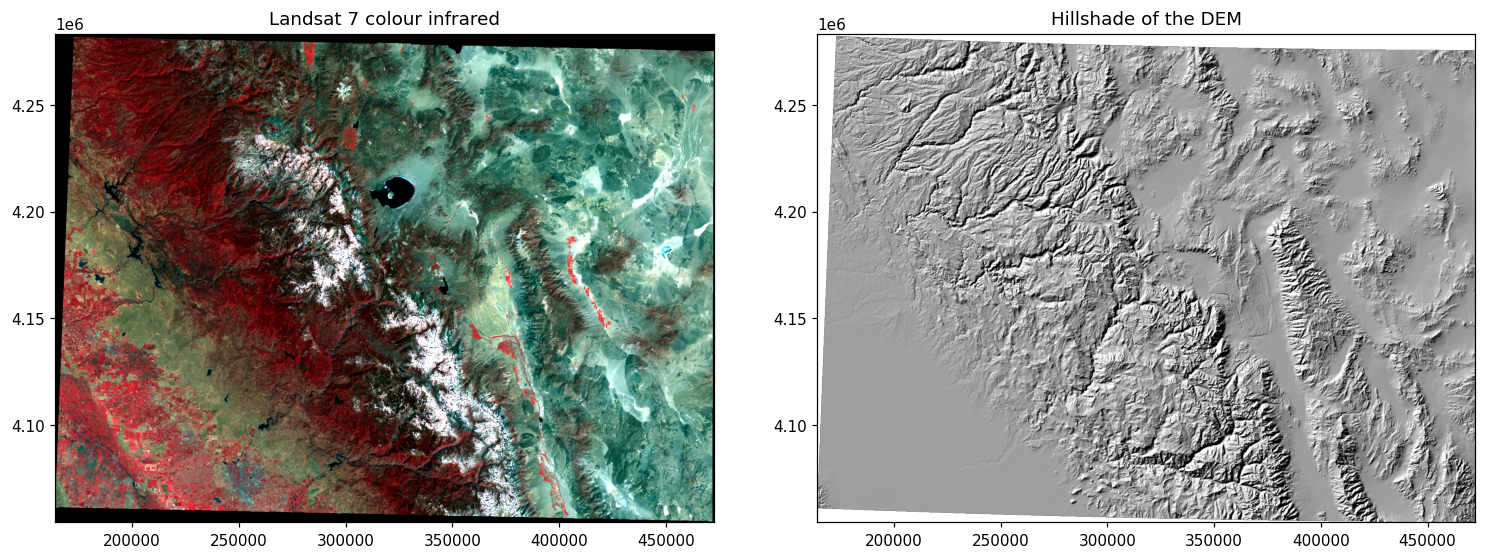

In [6]:
# the Landsat 7 image with band names
img = rs.read(fetch("landsat.tif"), band_names=["blue", "green", "red", "nir"])
# zero = no data; reproject to UTM 11N at 180 m
img = img.where(img > 0).rio.reproject("EPSG:32611", resolution=180, resampling=Resampling.bilinear)
img = img.where(img > 0) / 255.0  # DN (0-255) -> 0-1
dem = rs.read(fetch("dem_90m.tif")).squeeze("band", drop=True).astype("float32")  # the DEM as floats
# average the DEM onto the image grid
dem = dem.rio.reproject_match(img.isel(band=0), resampling=Resampling.average)
dem = dem.where(dem > -100)  # mask invalid elevations
ds = img.to_dataset(dim="band").rio.write_crs("EPSG:32611")  # bands as variables, with the CRS
fig, axes = plt.subplots(1, 2, figsize=(14, 5))  # two panels
rs.viz.plot_rgb(ds, "false_color", ax=axes[0], title="Landsat 7 colour infrared")  # colour infrared
# hillshade
rs.viz.plot_raster(rs.lidar.hillshade(dem), ax=axes[1], cmap="gray", title="Hillshade of the DEM", colorbar=False)
plt.tight_layout(); plt.show()  # arrange and draw

This is a five-year composite, so there is no single sun position in the metadata. We can
**estimate** it from the image: for a given azimuth and elevation, compute cos *i* and find the
geometry that best explains the brightness pattern of vegetated pixels.


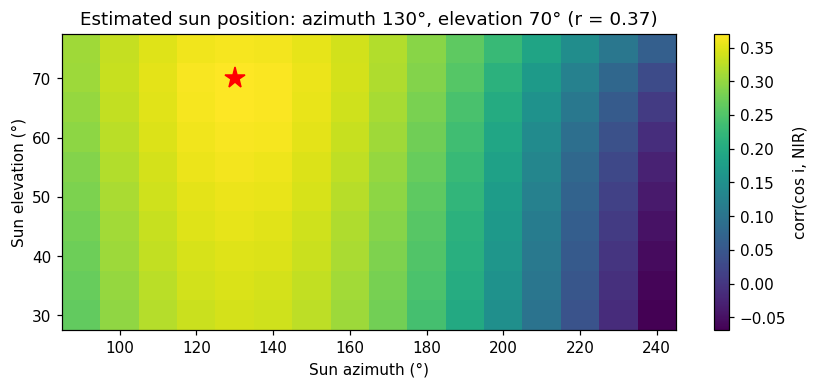

In [7]:
ndvi = ds.rs.index("NDVI")  # NDVI
veg = (ndvi > 0.3) & dem.notnull()  # vegetated pixels with elevation
nir = ds["nir"].values  # NIR as an array
best = (-1, None)  # best (correlation, (azimuth, elevation)) so far
grid = []  # every tested sun position
for az in range(90, 241, 10):  # sun azimuths 90-240 degrees
    for el in range(30, 76, 5):  # sun elevations 30-75 degrees
        # cosine of the solar incidence angle for this sun position
        ci = rs.lidar.illumination(dem, az, el).values
        m = veg.values & np.isfinite(ci) & np.isfinite(nir)  # vegetated, valid pixels
        r = np.corrcoef(ci[m], nir[m])[0, 1]  # correlation between illumination and NIR
        grid.append((az, el, r))  # store it
        if r > best[0]:  # strongest correlation so far
            best = (r, (az, el))  # keep this sun position
r_best, (SUN_AZ, SUN_EL) = best  # the best sun position
# correlations as an elevation x azimuth table
g = pd.DataFrame(grid, columns=["az", "el", "r"]).pivot(index="el", columns="az", values="r")
fig, ax = plt.subplots(figsize=(9, 3.5))  # one panel
im = ax.imshow(g, origin="lower", aspect="auto", cmap="viridis",  # the correlation surface
               extent=[g.columns.min() - 5, g.columns.max() + 5, g.index.min() - 2.5, g.index.max() + 2.5])
# the best position and a colour bar
ax.plot(SUN_AZ, SUN_EL, "r*", ms=14); plt.colorbar(im, label="corr(cos i, NIR)")
ax.set(xlabel="Sun azimuth (°)", ylabel="Sun elevation (°)",  # labels and title
       title=f"Estimated sun position: azimuth {SUN_AZ}°, elevation {SUN_EL}° (r = {r_best:.2f})")
plt.show()  # draw

The estimate (a south-east, fairly high sun) is consistent with mid-morning summer acquisitions
of Landsat at 37-38° N. Now we apply the four correction methods and measure how much
illumination dependence remains, using vegetated pixels only to fit the empirical coefficients.


In [8]:
cos_i = rs.lidar.illumination(dem, SUN_AZ, SUN_EL)  # solar illumination with the estimated sun position
results = {"original": ds}  # uncorrected image
for method in ["cosine", "c", "minnaert", "scs+c"]:  # four topographic correction methods
    # correct the image, fitting on vegetation only
    results[method] = rs.optical.topographic_correction(ds, dem, SUN_AZ, SUN_EL, method=method, mask=veg)

ci = cos_i.values  # illumination as an array
m = veg.values & np.isfinite(ci)  # vegetated, valid pixels
aspect = rs.lidar.aspect(dem).values  # aspect in degrees
north = m & ((aspect > 315) | (aspect < 45)) & (rs.lidar.slope(dem).values > 15)  # steep north-facing slopes
south = m & (aspect > 135) & (aspect < 225) & (rs.lidar.slope(dem).values > 15)  # steep south-facing slopes
rows = {}  # statistics per method
for name, r in results.items():  # every method
    v = r["nir"].values  # its NIR band
    ok = m & np.isfinite(v)  # valid pixels
    # illumination correlation and north/south contrast
    rows[name] = {"corr(cos i, NIR)": np.corrcoef(ci[ok], v[ok])[0, 1],
                  "NIR south/north slope ratio": np.nanmean(v[south]) / np.nanmean(v[north]),
                  "NIR CV (vegetated)": np.nanstd(v[ok]) / np.nanmean(v[ok])}
pd.DataFrame(rows).T.round(3)  # show the table

,"corr(cos i, NIR)",NIR south/north slope ratio,NIR CV (vegetated)
original,0.371,1.319,0.246
cosine,0.109,1.101,0.227
c,-0.026,1.023,0.226
minnaert,0.018,1.046,0.225
scs+c,0.116,1.028,0.229


A good correction drives the correlation with cos *i* towards zero and the south/north ratio
towards 1 without inflating variability. All four methods help. The empirical **C** and
**Minnaert** corrections remove the illumination effect almost completely; the **cosine** method
and **SCS+C** leave part of it. The cosine method has no fitted coefficient: it assumes surfaces
reflect equally in all directions and ignores diffuse skylight, which is why it is known to
over-correct poorly lit slopes. Which empirical method wins varies by scene and land cover, so
measure it as done here rather than assuming.


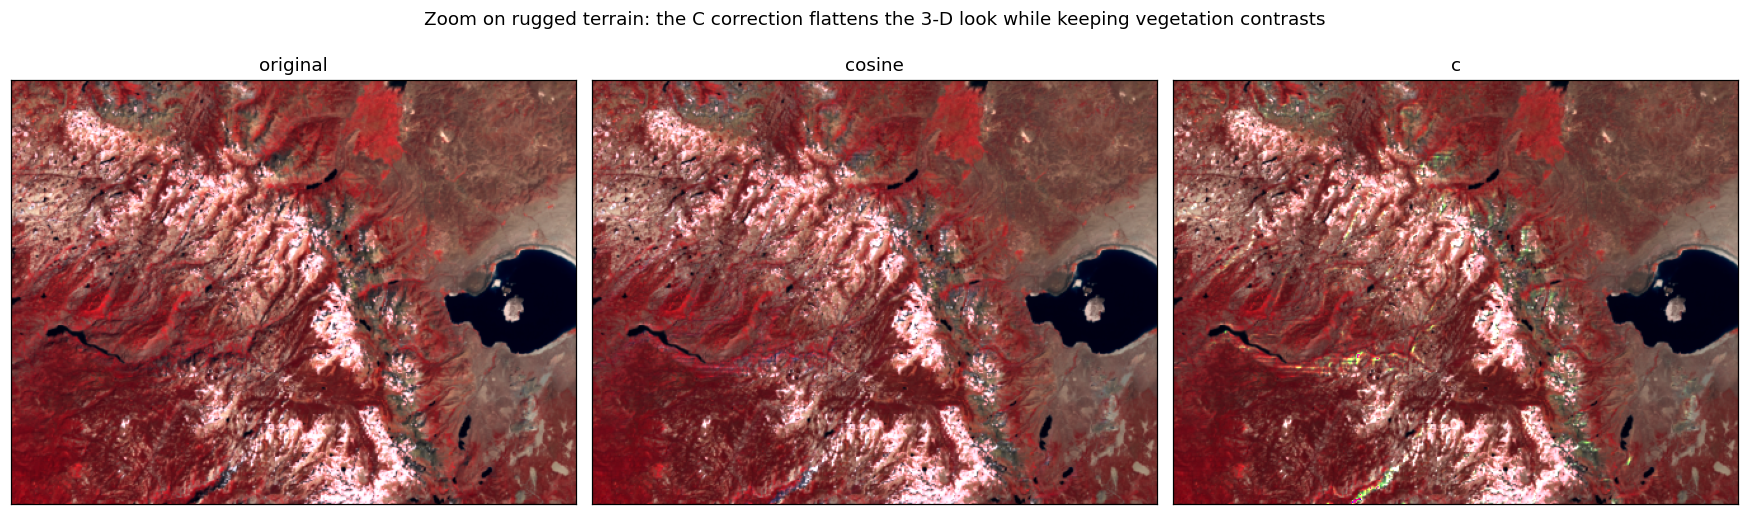

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))  # three panels
# a zoom window on rugged terrain (UTM metres)
win = dict(x=slice(250_000, 330_000), y=slice(4_240_000, 4_180_000))
for ax, name in zip(axes, ["original", "cosine", "c"]):  # original, cosine and C correction
    # colour infrared of the zoom
    rs.viz.plot_rgb(results[name].sel(win), "false_color", ax=ax, per_band=False, title=name)
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
# overall title
plt.suptitle("Zoom on rugged terrain: the C correction flattens the 3-D look while keeping vegetation contrasts")
plt.tight_layout(); plt.show()  # arrange and draw

## Cloud-free compositing

Composites merge several cloud-masked dates into one image. Methods trade cleanliness against
spectral consistency (whether all bands of a pixel come from the same date). We composite the
2016-2017 summer (June-September) Sentinel-2 dates with each method in `rs.optical.composite`.


In [10]:
season = s2c.sel(time=s2c.time.dt.month.isin([6, 7, 8, 9]))  # cloud-masked summer dates
season = season[["B02", "B03", "B04", "B05", "B08", "B11", "B12"]]  # bands used for compositing
print(f"{season.sizes['time']} summer dates, mean clear fraction "  # number of dates and mean clear share
      f"{float(clear.sel(time=season.time).mean()):.0%}")
# compositing methods and their options
methods = {"median": {}, "mean": {}, "percentile": {"q": 25}, "max_index": {"index": "NDVI"},
           "median_nearest": {}, "bap": {"target_doy": 200}}
comps = {m: rs.optical.composite(season, m, **kw) for m, kw in methods.items()}  # build every composite

32 summer dates, mean clear fraction 60%


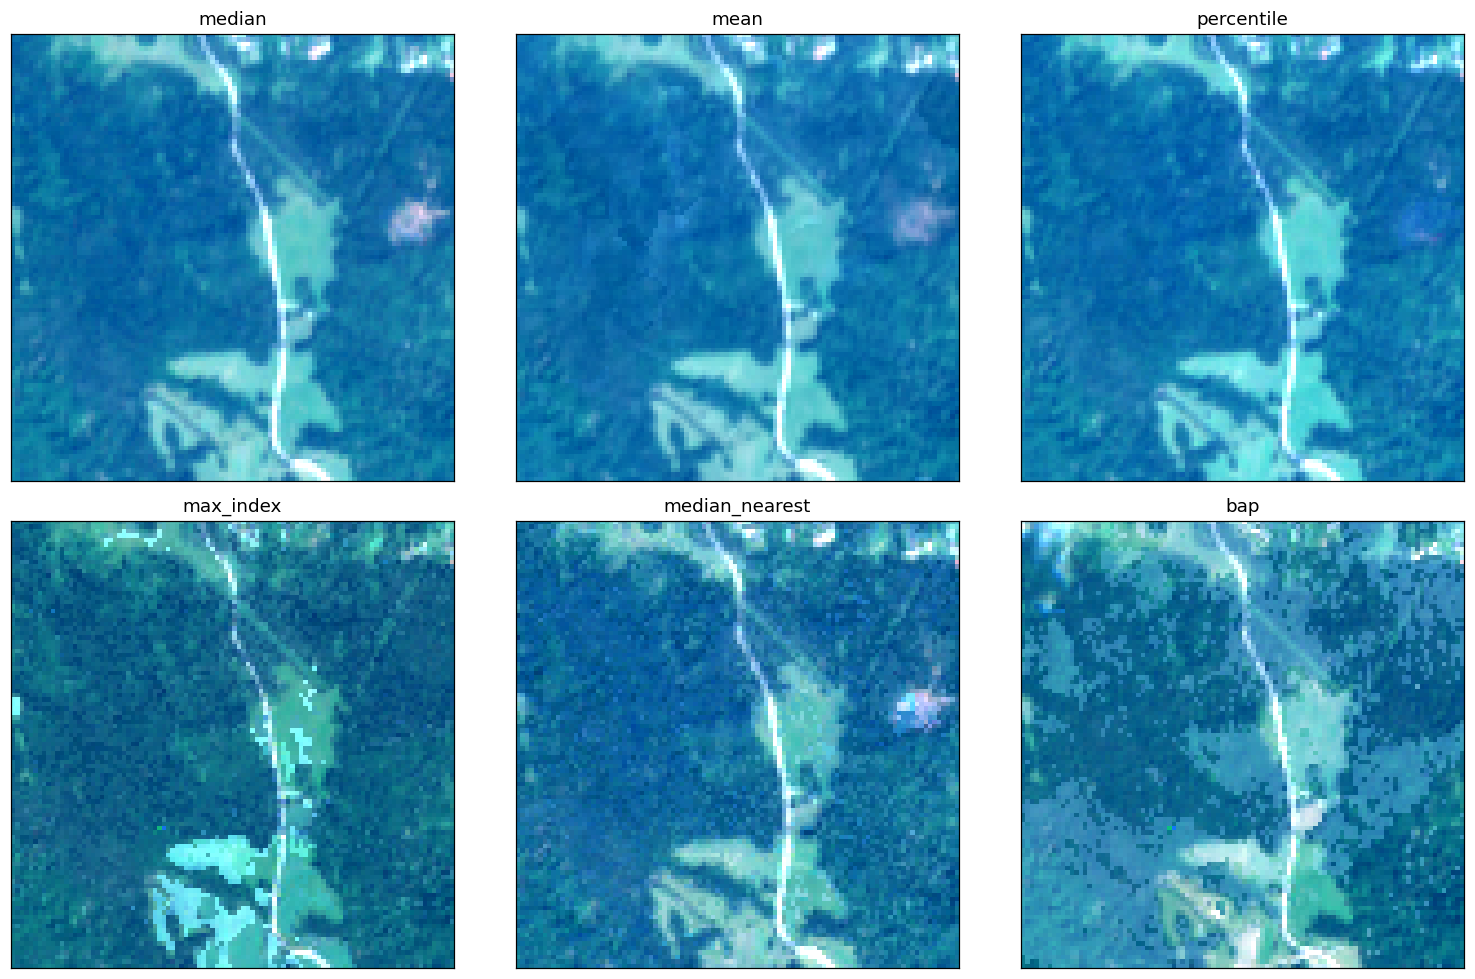

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14, 9))  # 2 x 3 panels
for ax, (m, c) in zip(axes.ravel(), comps.items()):  # every composite
    # true colour with a 1-99 % stretch
    rs.viz.plot_rgb(c, ["B04", "B03", "B02"], ax=ax, per_band=False, p=(1, 99), title=m)
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw

To compare quantitatively we use three checks: **residual haze/cloud** (share of pixels with
TOA blue reflectance > 0.12, well above clear vegetation even with haze in this scene), **gaps** (pixels with no value),
and **spectral realism**: the distance of each composite pixel's spectrum to the nearest *real*
clear observation of that pixel. Per-band statistics (median, mean, percentile) mix dates, so
their spectra need not match any real observation; selection methods keep real spectra.


In [12]:
obs = np.stack([season[v].values for v in season.data_vars], -1)        # (t, y, x, b)
rows = {}  # statistics per method
for m, c in comps.items():  # every composite
    comp = np.stack([c[v].values for v in season.data_vars], -1)       # (y, x, b)
    d = np.sqrt(np.nansum((obs - comp[None]) ** 2, -1))  # spectral distance of each date to the composite
    d[np.all(np.isnan(obs), -1)] = np.nan  # NaN where a pixel was never clear
    # residual haze and distance to the observations
    rows[m] = {"residual haze/cloud (blue > 0.12)": float(np.nanmean(c["B02"].values > 0.12)),
               "gaps": float(np.isnan(c["B04"].values).mean()),
               "distance to nearest real spectrum": float(np.nanmean(np.nanmin(d, 0))),
               "mean NDVI": float(rs.optical.index(c, "NDVI").mean())}
pd.DataFrame(rows).T.round(4)  # show the table

,residual haze/cloud (blue > 0.12),gaps,distance to nearest real spectrum,mean NDVI
median,0.0025,0.0,0.0101,0.6894
mean,0.0022,0.0,0.0130,0.6726
percentile,0.0006,0.0,0.0100,0.6810
max_index,0.0027,0.0,0.0000,0.7567
median_nearest,0.0024,0.0,0.0000,0.6957
bap,0.0031,0.0,0.0000,0.7125


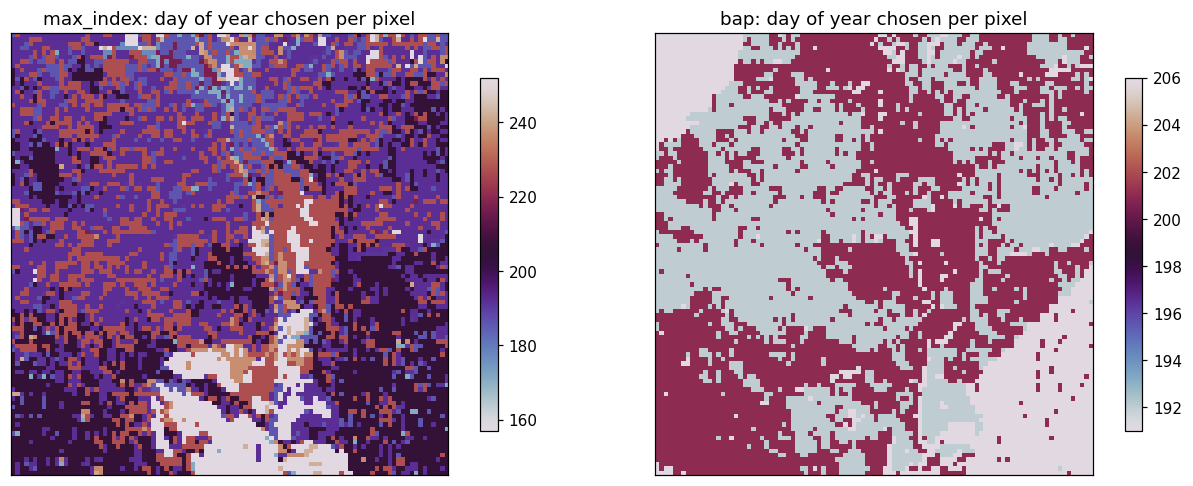

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))  # two panels
for ax, m in zip(axes, ["max_index", "bap"]):  # the two methods that pick one date per pixel
    src = comps[m]["source_time"]  # the chosen date of every pixel
    doy = xr.where(src.notnull(), src.dt.dayofyear, np.nan)  # as day of year
    rs.viz.plot_raster(doy, ax=ax, cmap="twilight", title=f"{m}: day of year chosen per pixel")  # map it
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw

Max-NDVI favours the greenest date (often mid-summer) and so biases vegetation upward, which is
fine for vegetation mapping but not for soils or change detection. BAP balances date proximity,
distance from clouds and greenness, choosing more consistent dates. Median-nearest is robust to
residual cloud and keeps real spectra, making it a good general default.


## Pan-sharpening and Wald's protocol

Landsat 8/9 have a 15 m panchromatic band alongside 30 m multispectral bands. Pan-sharpening
injects the pan detail into the colour bands. To *evaluate* it we use **Wald's protocol**:
degrade everything by the resolution ratio, sharpen the degraded data, and compare with the
original, which serves as ground truth.

Our scene is at 90 m, so we simulate a 90 m pan band from the visible bands (OLI's pan covers
500-680 nm), degrade the multispectral bands to 270 m, sharpen back to 90 m, and score against
the true 90 m bands with RMSE, correlation and **ERGAS** (lower is better; < 3 is good).


In [14]:
ls = rs.read(fetch("landsat_las_vegas.tif"),  # a Landsat scene of Las Vegas
             band_names=["coastal", "blue", "green", "red", "nir", "swir16", "swir22"], as_dataset=True)
# mask zero red, clip to small positive values and set the CRS
ls = ls.where(ls["red"] > 0).clip(min=1e-4).rio.write_crs(32611)
ls.attrs["pyrsense:sensor"] = "landsat"  # record the sensor
sub = ls.isel(x=slice(300, 750), y=slice(150, 600))                        # 450 × 450 px, city centre
truth = sub[["red", "green", "blue"]]  # the reference (true) RGB at 90 m
# synthetic panchromatic band: weighted sum of blue, green and red
pan = (0.25 * sub["blue"] + 0.4 * sub["green"] + 0.35 * sub["red"]).rio.write_crs(32611)
ms_coarse = truth.coarsen(x=3, y=3, boundary="trim").mean()  # multispectral degraded 3x (270 m)
ms_coarse = ms_coarse.drop_vars("spatial_ref").rio.write_crs(32611)   # drop the stale 90 m transform
# resolutions of the two inputs
print("MS degraded to", ms_coarse.rio.resolution(), "| pan at", pan.rio.resolution())

def ergas(fused, ref, ratio):  # ERGAS: relative error across bands, scaled by the resolution ratio
    # relative RMSE of each band
    terms = [(np.sqrt(np.nanmean((fused[b].values - ref[b].values) ** 2)) / np.nanmean(ref[b].values)) ** 2
             for b in ref.data_vars]
    return 100 / ratio * np.sqrt(np.mean(terms))  # ERGAS formula

# baseline: bilinear upsampling without the pan band
out = {"bilinear (no pan)": xr.Dataset({b: ms_coarse[b].rio.reproject_match(pan, resampling=Resampling.bilinear)
                                        for b in truth.data_vars})}
for method in ["brovey", "ihs", "hpf"]:  # three pan-sharpening methods
    # fuse the coarse bands with the pan band
    out[method] = rs.optical.pansharpen(ms_coarse, pan, method=method)
scores = {}  # scores per method
for name, f in out.items():  # every result
    f = f.assign_coords(x=truth.x, y=truth.y)  # same coordinates as the reference
    scores[name] = {"ERGAS": ergas(f, truth, 3),  # ERGAS and other scores
                    "RMSE (red)": float(np.sqrt(np.nanmean((f["red"] - truth["red"]) ** 2))),
                    "corr (red)": float(xr.corr(f["red"], truth["red"]))}
pd.DataFrame(scores).T.round(4)  # show the table

MS degraded to (270.0, -270.0) | pan at (90.0, -90.0)


,ERGAS,RMSE (red),corr (red)
bilinear (no pan),7.0761,0.0460,0.7814
brovey,1.4115,0.0089,0.9969
ihs,1.6350,0.0094,0.9947
hpf,2.2535,0.0124,0.9857


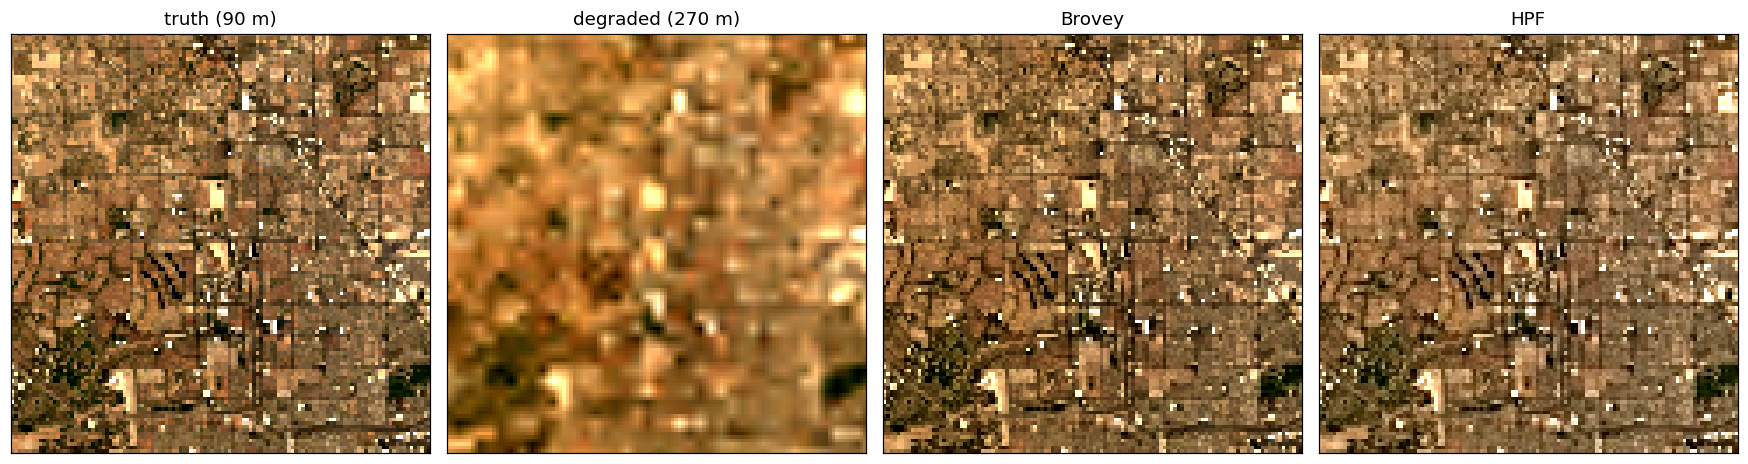

In [15]:
zoom = dict(x=slice(100, 220), y=slice(100, 220))  # a zoom window (pixels)
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))  # four panels
# images and titles
show = [("truth (90 m)", truth), ("degraded (270 m)", out["bilinear (no pan)"]), ("Brovey", out["brovey"]),
        ("HPF", out["hpf"])]
for ax, (t, d) in zip(axes, show):  # every panel
    # true colour of the zoom
    rs.viz.plot_rgb(d.assign_coords(x=truth.x, y=truth.y).isel(zoom), ["red", "green", "blue"], ax=ax,
                    per_band=False, title=t)
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw

All three sharpening methods beat plain upsampling by a wide margin. Brovey and IHS score best
here, partly because our simulated pan band is an exact weighted sum of the visible bands; a real
pan band has a broader response, which usually costs Brovey colour fidelity. HPF injects detail
more conservatively. Remember that Wald's protocol assumes the quality ranking is
scale-invariant, a reasonable but untestable assumption.


## Co-registration

Images from different dates or sensors can be offset by a fraction of a pixel to a few pixels.
Unnoticed, this creates false change along every edge. `rs.optical.coregister` estimates the
translation by sub-pixel phase correlation and resamples the image to match.

First a controlled test: shift a real Sentinel-2 band by a known amount and recover it.


In [16]:
from scipy.ndimage import shift as nd_shift  # shift an image by a sub-pixel amount
ref = s2["B08"].isel(time=k)  # the NIR band of the clear date
true_shift = (1.6, -2.3)                                   # rows, cols (pixels)
# a copy shifted by a known amount
moved = ref.copy(data=nd_shift(ref.values, true_shift, order=3, mode="nearest"))
# estimate the shift and correct it (1/50 pixel precision)
fixed, info = rs.optical.coregister(moved, ref, upsample=50)
inner = (slice(6, -6), slice(6, -6))  # interior pixels (edges are affected by the shift)
# applied vs estimated shift
print(f"Applied shift: {true_shift} px → estimated correction: ({info['dy']:.2f}, {info['dx']:.2f}) px")
# mean difference to the reference before and after
print(f"Mean |difference| to reference: before {np.nanmean(np.abs(moved.values - ref.values)[inner]):.4f}, "
      f"after {np.nanmean(np.abs(fixed.values - ref.values)[inner]):.4f}")

Applied shift: (1.6, -2.3) px → estimated correction: (-1.58, 2.26) px
Mean |difference| to reference: before 0.0390, after 0.0077


In [17]:
# Real data: how well are clear Sentinel-2 dates aligned with each other?
clear_dates = [i for i in range(len(times)) if clp[i].mean() < 0.05][:12]
rows = []  # offsets of every clear date
for i in clear_dates[1:]:  # every clear date except the reference
    # estimate its offset against the reference date
    _, inf = rs.optical.coregister(s2["B08"].isel(time=i), s2["B08"].isel(time=clear_dates[0]),
                                   apply=False, upsample=50)
    # offset in metres (10 m pixels)
    rows.append((times[i].date(), round(inf["dy"] * 10, 2), round(inf["dx"] * 10, 2)))
off = pd.DataFrame(rows, columns=["date", "dy (m)", "dx (m)"])  # as a table
print(f"Reference date {times[clear_dates[0]].date()}; median |offset| = "  # reference date and median offset
      f"{np.median(np.hypot(off['dy (m)'], off['dx (m)'])):.1f} m")
off  # show the table

Reference date 2015-07-11; median |offset| = 8.2 m


,date,dy (m),dx (m)
0,2015-08-30,4.2,-0.2
1,2015-09-09,9.0,3.6
2,2016-01-07,18.2,6.8
3,2016-05-26,5.2,1.6
4,2016-08-04,3.8,2.6
5,2016-08-14,5.4,1.0
6,2016-09-23,8.2,-0.4
7,2017-04-01,10.6,4.0
8,2017-04-21,8.2,2.6
9,2017-05-21,9.0,3.2


These 2015-2017 dates are offset by up to about one 10 m pixel (more on the January date, where
snow makes the correlation less reliable). That is typical of early Sentinel-2 processing; the
2021 refinement against the Global Reference Image brought multi-temporal registration well
below a pixel. For high-precision change detection, older archives, or combinations of sensors
(e.g. Landsat with Sentinel-2), co-register explicitly.


## Linear spectral unmixing

A 90 m pixel in a city mixes roofs, roads, trees, lawns and soil. Linear unmixing models each
pixel spectrum as a fraction-weighted sum of pure **endmember** spectra. We take endmembers from
the image, guided by NLCD: vegetation (greenest pixels), impervious (high-intensity developed,
low NDVI), soil (barren/shrubland, low NDVI) and water (Lake Mead).


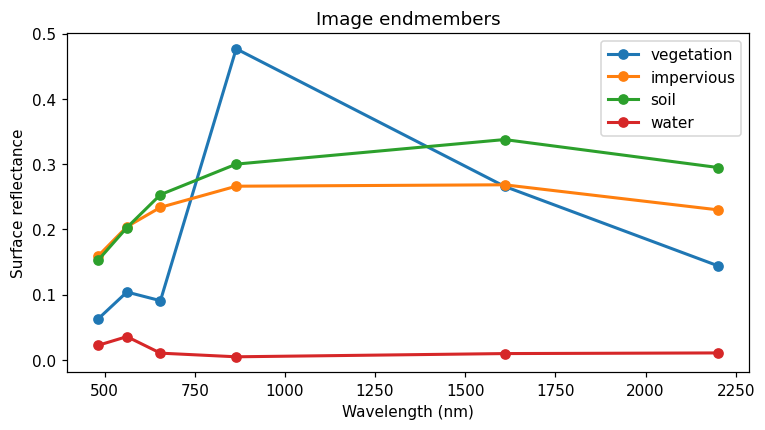

In [18]:
nlcd = nlcd_for(ls["red"])  # NLCD land cover on the Landsat grid
nd = ls.rs.index("NDVI")  # NDVI
rng = np.random.default_rng(0)  # random generator

def sample(mask, n=150):  # random sample of up to n pixels from a mask
    rr, cc = np.nonzero(mask.values)  # rows and columns of the mask pixels
    idx = rng.choice(rr.size, min(n, rr.size), replace=False)  # random indices
    return pd.DataFrame({"x": ls.x.values[cc[idx]], "y": ls.y.values[rr[idx]]})  # their map coordinates

pure = {  # masks of pure pixels for each endmember
    "vegetation": nd > float(nd.quantile(0.998)),
    "impervious": (nlcd == 24) & (nd < 0.12),
    "soil": nlcd.isin([31, 52]) & (nd < 0.1),
    "water": (nlcd == 11) & (ls["nir"] < 0.02),
}
# sample points of all classes
pts = pd.concat([sample(m).assign(cls=k) for k, m in pure.items()], ignore_index=True)
pts = gpd.GeoDataFrame(pts, geometry=gpd.points_from_xy(pts.x, pts.y), crs=32611)  # as a GeoDataFrame
bands6 = ["blue", "green", "red", "nir", "swir16", "swir22"]  # the six reflective bands
E = rs.optical.endmembers_from_samples(ls, pts, "cls", bands=bands6)  # mean spectrum of each class = endmembers
wl = [482, 562, 655, 865, 1609, 2201]  # band centre wavelengths (nm)
fig, ax = plt.subplots(figsize=(8, 4))  # one panel
for kname, spec in E.items():  # every endmember
    ax.plot(wl, spec, "o-", label=kname, lw=2)  # its spectrum
# labels, title, legend and draw
ax.set(xlabel="Wavelength (nm)", ylabel="Surface reflectance", title="Image endmembers"); ax.legend(); plt.show()

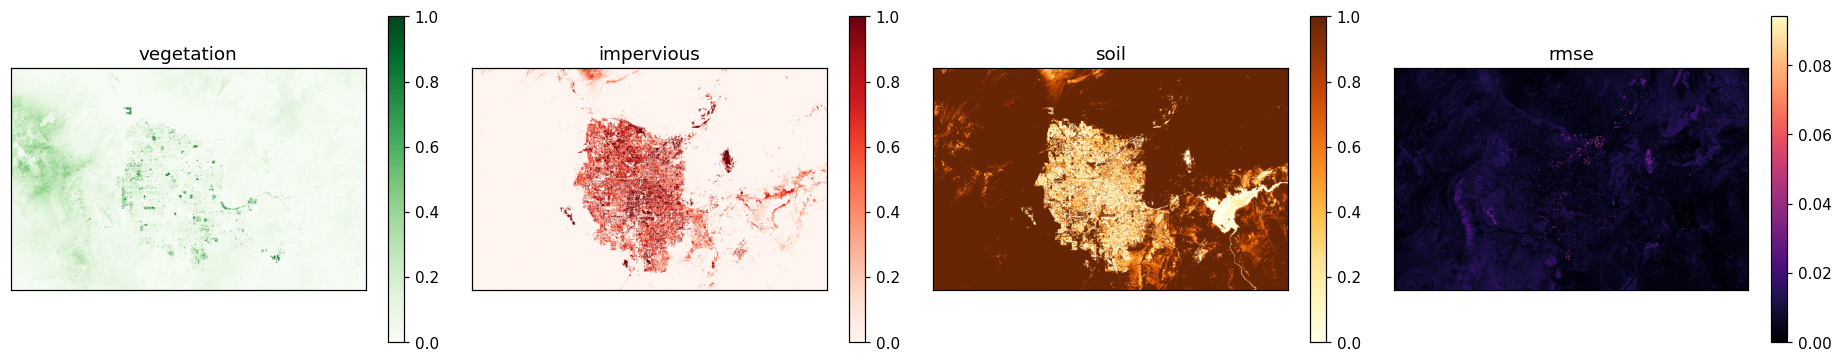

In [19]:
frac = rs.optical.unmix(ls, E, bands=bands6, method="scls")  # sum-to-one constrained unmixing
fig, axes = plt.subplots(1, 4, figsize=(17, 4))  # four panels
# three fractions and the residual error
for ax, kname, cm in zip(axes, ["vegetation", "impervious", "soil", "rmse"], ["Greens", "Reds", "YlOrBr", "magma"]):
    # map each layer (fractions clipped to 0-1)
    rs.viz.plot_raster(frac[kname].clip(0, 1) if kname != "rmse" else frac[kname], ax=ax, cmap=cm,
                       vmin=0, vmax=1 if kname != "rmse" else None, title=kname)
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw

In [20]:
# Fully constrained (non-negative, sum-to-one) unmixing on a subset, compared with SCLS
sub_ds = ls.isel(x=slice(400, 520), y=slice(250, 370))
# fully constrained unmixing (non-negative, sum to one)
fc = rs.optical.unmix(sub_ds, E, bands=bands6, method="fcls")
sc = rs.optical.unmix(sub_ds, E, bands=bands6, method="scls")  # sum-to-one constrained only
# share of negative fractions in each
pd.DataFrame({m: {"negative fractions": float((f[list(E)].to_array() < 0).mean()),
                  "mean RMSE": float(f["rmse"].mean())} for m, f in [("SCLS", sc), ("FCLS", fc)]}).T.round(4)

,negative fractions,mean RMSE
SCLS,0.2227,0.0057
FCLS,0.0000,0.0178


Validation: if the fractions are meaningful, the impervious fraction should rise from NLCD's
"developed, open" to "developed, high intensity", and vegetation should be highest in forests.


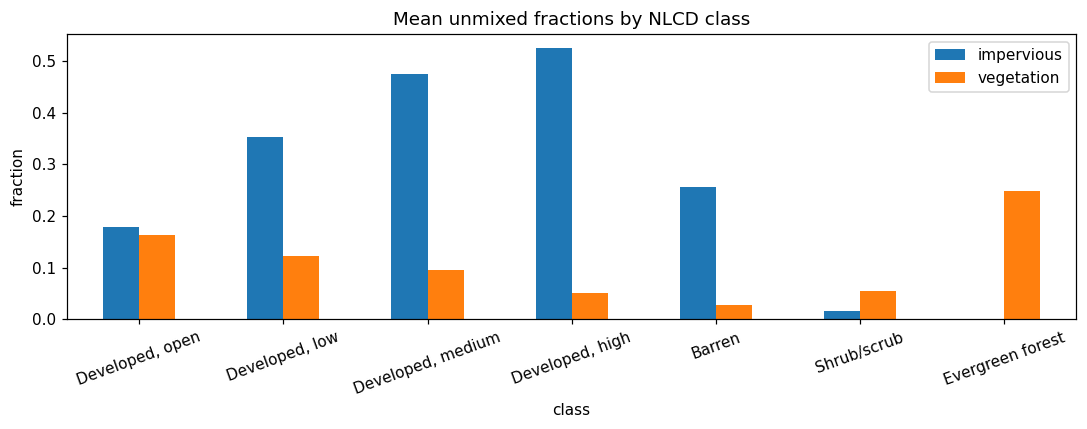

,impervious,vegetation
class,,
"Developed, open",0.179,0.163
"Developed, low",0.354,0.122
"Developed, medium",0.476,0.095
"Developed, high",0.526,0.051
Barren,0.256,0.027
Shrub/scrub,0.016,0.054
Evergreen forest,0.000,0.249


In [21]:
# NLCD class, impervious and vegetation fraction of every pixel
df = pd.DataFrame({"code": nlcd.values.ravel(), "impervious": frac["impervious"].clip(0, 1).values.ravel(),
                   "vegetation": frac["vegetation"].clip(0, 1).values.ravel()}).dropna()
df = df[df.code.isin([21, 22, 23, 24, 31, 42, 52])]  # keep developed, barren, forest and shrub classes
df["class"] = df.code.map(lambda c: NLCD_CLASSES[c][0])  # class names
# plotting order
order = ["Developed, open", "Developed, low", "Developed, medium", "Developed, high", "Barren",
         "Shrub/scrub", "Evergreen forest"]
summary = df.groupby("class")[["impervious", "vegetation"]].mean().reindex(order)  # mean fractions per class
summary.plot(kind="bar", figsize=(10, 4), rot=20, title="Mean unmixed fractions by NLCD class")  # bar chart
plt.ylabel("fraction"); plt.tight_layout(); plt.show()  # label, arrange and draw
summary.round(3)  # show the table

The impervious fraction increases monotonically with NLCD development intensity and vegetation
peaks in evergreen forest, so the fractions carry real information even with simple image
endmembers. Known limitations: bright soils and roofs are spectrally similar (they trade off
against each other), and a single spectrum per class ignores within-class variability (multiple
endmember methods such as MESMA address this).


## Summary, exercises and references

**Key ideas**

- Indices and multi-date comparisons need surface reflectance; DOS1 is a quick fallback.
- Terrain illumination can dominate brightness in mountains; empirical C/SCS+C corrections work
  best, and the sun position can even be estimated from the image.
- Compositing methods differ in cleanliness and spectral realism; selection methods
  (median-nearest, BAP) keep real spectra.
- Evaluate pan-sharpening with Wald's protocol and ERGAS rather than by eye.
- Check co-registration before change detection, especially across sensors.
- Unmixing turns mixed pixels into interpretable sub-pixel fractions; validate them.

**`geolattice.rsense` functions used:** `rs.optical.dos1`, `rs.lidar.illumination/hillshade/slope/aspect`,
`rs.optical.topographic_correction`, `rs.optical.composite`, `rs.optical.pansharpen`,
`rs.optical.coregister`, `rs.optical.endmembers_from_samples`, `rs.optical.unmix`.

**Exercises**

1. Fit the topographic C coefficient per land-cover class instead of for all vegetation.
   Does SCS+C improve further?
2. Add a 30th-percentile composite and a `bap` composite with `target_doy=240`. How do haze and
   NDVI change?
3. Repeat the Wald test with a 1:2 ratio (180 m) instead of 1:3. Does the ranking change?
4. Co-register a Landsat 9 scene to a Sentinel-2 scene of the same area (notebook 07_01_03 loaders).
5. Add a "dark impervious" (asphalt) endmember and see whether the soil/roof confusion drops.

**Next:** Notebook 07_02_03 works with MODIS, the daily global record.
